In [1]:
%matplotlib inline
import hcipy as hci
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class FocalPlaneMask(hci.OpticalElement):
    def __init__(self, input_grid, opacity_ftn):
        self.grid = input_grid
        self.opacity_ftn = opacity_ftn
    def forward(self, wavefront):
        return self.opacity_ftn*wavefront
        print("self.opacity_ftn\n{}\n".format(self.opacity_ftn))
        print("wavefront\n{}\n".format(wavefront))
    def backward(self, wavefront):
        return self.opacity_ftn*wavefront

In [3]:
class SleecCoronagraph(hci.OpticalElement):
    
    def __init__(self, input_grid, focal_plane_mask, lyot_stop=None):
        if hasattr(focal_plane_mask, 'input_grid'):
            grid = focal_plane_mask.input_grid
            self.focal_plane_mask = focal_plane_mask
        else:
            grid = focal_plane_mask.grid
            self.focal_plane_mask = hci.Apodizer(focal_plane_mask)
        if lyot_stop is not None and not hasattr(lyot_stop, 'input_grid'):
            lyot_stop = hci.Apodizer(lyot_stop)
        self.lyot_stop = lyot_stop
        self.prop = hci.FraunhoferPropagator(input_grid, focal_plane_mask.grid)
        
    def forward(self, wavefront):
        wf_foc = self.prop.forward(wavefront)  # Field incident on FPM
        print("wf_foc.electric_field\n{}\n".format(wf_foc.electric_field))
        print("self.focal_plane_mask.forward(wf_foc.electric_field)\n{}\n"
              .format(self.focal_plane_mask.forward(wf_foc).electric_field))
        print("Debug:  I'm here")
        wf_foc.electric_field -= self.focal_plane_mask.forward(wf_foc).electric_field 
            # (field inc. on FPM) - [transmssn_ftn*(field inc on FPM)]
        
        lyot = self.prop.backward(wf_foc)
        lyot.electric_field[:] = wavefront.electric_field - lyot.electric_field
        
        if self.lyot_stop is not None:
            lyot = self.lyot_stop.forward(lyot)
            
        return lyot
    
    def backward(self, wavefront):
        if self.lyot_stop is not None:
            wf = self.lyot_stop.backward(wavefront)
        else:
            wf = wavefront
            
        wf_foc = self.prop.forward(wf)
        wf_foc.electric_field -= self.focal_plane_mask.backward(wf_foc).electric_field
        
        pup = self.prop.backward(wf_foc)
        pup.electric_field[:] = wavefront.electric_field = wf_foc.electric_field
        
        return pup

In [4]:
pupil_grid = hci.make_pupil_grid(128)
focal_grid = hci.make_focal_grid(pupil_grid, 8, 32)
prop = hci.FraunhoferPropagator(pupil_grid, focal_grid)

In [5]:
aperture = hci.circular_aperture(3)
fpm_opacity = aperture(focal_grid)
fpm = FocalPlaneMask(focal_grid, fpm_opacity)
pupil = hci.Wavefront(hci.circular_aperture(1)(pupil_grid))

In [6]:
coro = SleecCoronagraph(pupil_grid, fpm)

In [7]:
test_a = coro.prop.forward(pupil)
print(test_a.electric_field)

[ 1.55036804e-18-0.00062j     2.42967169e-18-0.00063074j
  3.73864839e-18-0.00059689j ... -7.49504114e-18-0.00025856j
 -3.63470740e-18-0.00041545j -2.91139281e-18-0.00054353j]


wf_foc.electric_field
[ 1.55036804e-18-0.00062j     2.42967169e-18-0.00063074j
  3.73864839e-18-0.00059689j ... -7.49504114e-18-0.00025856j
 -3.63470740e-18-0.00041545j -2.91139281e-18-0.00054353j]

self.focal_plane_mask.forward(wf_foc.electric_field)
[0.+0.j 0.+0.j 0.+0.j ... 0.-0.j 0.-0.j 0.-0.j]

Debug:  I'm here


/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


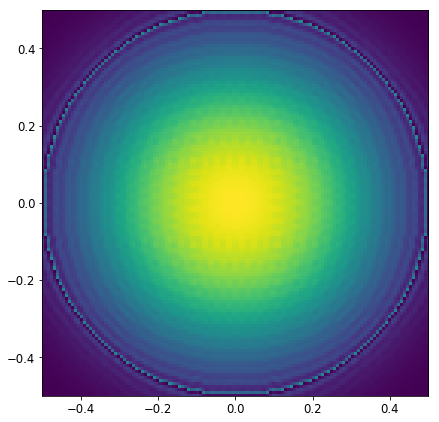

In [9]:
lyot_plane = coro(pupil)
hci.imshow_field(lyot_plane.intensity)